# 06 · Word Embeddings and Sequence-to-Sequence Translation

Images are grids of numbers and time series are lists of numbers, but **words are symbols**. Before a network can read text, every word has to become a vector, and *which* vector matters enormously. This notebook covers the two ideas that took neural networks from numbers to language:

| Part | Idea | Experiment |
|---|---|---|
| A · sections 1-5 | **word embeddings**: meaning as geometry | train word2vec-style embeddings from scratch, find analogies like *king − man + woman ≈ queen*, then measure and remove a gender bias planted in the training text |
| B · sections 6-10 | **encoder-decoder with attention** | translate English → Spanish with a GRU encoder, an attention decoder and beam search |

Everything runs on a CPU in a few minutes. Both corpora are generated in the notebook from small grammars, so every result is reproducible and nothing is downloaded.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import time, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0); np.random.seed(0); random.seed(0)
torch.set_num_threads(max(1, torch.get_num_threads()))
plt.rcParams["axes.grid"] = False
def count_params(m): return sum(p.numel() for p in m.parameters())

---
# Part A · Word embeddings

## 1. From one-hot vectors to dense vectors

The simplest encoding gives each of $V$ words its own position in a $V$-dimensional vector: *cat* = $[0,0,1,0,\dots]$. This **one-hot** encoding has a fatal flaw: every pair of words is equally far apart. *cat* is as similar to *dog* as it is to *Tuesday*, so nothing the network learns about one word helps with any other.

An **embedding** maps each word to a short dense vector (here 32 numbers instead of 148), stored as one row of a matrix $E \in \mathbb{R}^{V \times d}$. Looking up a word is just selecting a row, which is exactly a one-hot vector multiplied by $E$. The rows are learned, and the hope is that words used in similar ways end up close together.

What does "used in similar ways" mean? The **distributional hypothesis** (Harris 1954, Firth 1957): *"You shall know a word by the company it keeps."* *Paris* and *Rome* appear next to the same words (*capital*, *flew to*, *big city*), so a model that predicts context words from a word will be pushed to give them similar vectors.

In [2]:
E_toy = torch.randn(5, 3)                       # 5 words, 3-dimensional embeddings
one_hot = F.one_hot(torch.tensor(2), 5).float()  # word number 2
print("one-hot @ E  :", (one_hot @ E_toy).numpy().round(3))
print("row lookup   :", E_toy[2].numpy().round(3), "  (same thing, much cheaper)")

one-hot @ E  : [ 0.403  0.838 -0.719]
row lookup   : [ 0.403  0.838 -0.719]   (same thing, much cheaper)


## 2. A small corpus with hidden structure

Real embeddings are trained on billions of words. To see the same effects in seconds, we generate 60,000 sentences from a small grammar that has **structure we can check afterwards**:

* **people** that differ along three independent axes: gender (*man/woman*, *king/queen*), royalty (*king* lives in a *palace*) and age (*boy* goes to *school*);
* **geography**: countries, their capitals and their languages, connected by consistent phrases;
* **animals** and **food**, which appear in clearly different contexts;
* **occupations**, where we deliberately plant a **bias**: *engineer, pilot, mechanic, programmer* appear with *he* 85% of the time, *nurse, receptionist, nanny, secretary* with *she* 85% of the time. Real text has skews like this, and section 5 shows what they do to embeddings.

In [3]:
people = [  # (male, female, royal, young)
    ("man", "woman", False, False), ("boy", "girl", False, True), ("king", "queen", True, False),
    ("prince", "princess", True, True), ("father", "mother", False, False), ("son", "daughter", False, True),
    ("brother", "sister", False, True), ("uncle", "aunt", False, False), ("husband", "wife", False, False),
]
countries = [("france", "paris", "french"), ("spain", "madrid", "spanish"), ("italy", "rome", "italian"),
             ("germany", "berlin", "german"), ("portugal", "lisbon", "portuguese"), ("japan", "tokyo", "japanese"),
             ("china", "beijing", "chinese"), ("russia", "moscow", "russian"), ("greece", "athens", "greek"),
             ("poland", "warsaw", "polish")]
animals = ["dog", "cat", "horse", "cow", "sheep", "rabbit"]
foods = ["apple", "bread", "cheese", "rice", "soup", "cake"]
jobs_he = ["engineer", "pilot", "mechanic", "programmer"]   # occupations the biased corpus pairs mostly with "he"
jobs_she = ["nurse", "receptionist", "nanny", "secretary"]   # ... and mostly with "she"

def sentence(rng):
    r = rng.random()
    if r < 0.40:                                     # people: gender, royalty, age
        m, f, royal, young = rng.choice(people)
        female = rng.random() < 0.5
        p, pron, poss = (f, "she", "her") if female else (m, "he", "his")
        t = rng.random()
        if t < 0.35:
            return f"the {p} said that {pron} was tired"
        if t < 0.55:
            return f"{pron} is the {p} of the family" if not royal else f"{pron} is the {p} of the kingdom"
        if t < 0.80:
            if royal:
                return rng.choice([f"the {p} lives in the palace", f"the {p} wears a crown", f"the {p} rules the kingdom", f"the {p} sits on the throne"])
            return rng.choice([f"the {p} lives in a house", f"the {p} works in the town", f"the {p} walks to the market"])
        if young:
            return rng.choice([f"the young {p} plays in the garden", f"the {p} goes to school", f"the young {p} learns to read"])
        return rng.choice([f"the old {p} reads {poss} newspaper", f"the {p} drives {poss} car to work", f"the old {p} rests at home"])
    if r < 0.70:                                     # geography
        c, city, lang = rng.choice(countries)
        return rng.choice([f"{city} is the capital of {c}", f"people in {c} speak {lang}", f"in {city} people speak {lang}",
                           f"we flew to {city} last summer", f"we travelled to {c} last summer", f"{city} is a big city in {c}",
                           f"the {lang} language is spoken in {c}", f"{c} is a country in the world"])
    if r < 0.85:                                     # animals and food: two clear clusters
        if rng.random() < 0.5:
            a = rng.choice(animals)
            return rng.choice([f"the {a} eats grass in the field", f"the {a} runs across the farm", f"the farmer feeds the {a}", f"the {a} sleeps in the barn"])
        f_ = rng.choice(foods)
        return rng.choice([f"we eat {f_} for dinner", f"the {f_} is very tasty", f"she bought some {f_} at the market", f"he cooked {f_} in the kitchen"])
    job = rng.choice(jobs_he + jobs_she)             # occupations, with a deliberate gender skew
    skew = 0.85 if job in jobs_he else 0.15          # probability the sentence uses "he"
    pron, poss = ("he", "his") if rng.random() < skew else ("she", "her")
    return rng.choice([f"the {job} said that {pron} was tired", f"the {job} finished {poss} work", f"{pron} works as a {job}",
                       f"the {job} drives {poss} car to work"])

rng = random.Random(0)
corpus = [sentence(rng) for _ in range(60000)]
for s in corpus[:8]:
    print(" ", s)

  we eat rice for dinner
  the wife drives her car to work
  the receptionist finished her work
  in lisbon people speak portuguese
  the cheese is very tasty
  the boy works in the town
  the japanese language is spoken in japan
  he is the prince of the kingdom


## 3. Training: skip-gram with negative sampling

The **skip-gram** model (Mikolov et al., 2013, the "word2vec" paper) turns the distributional hypothesis into a training task: given a centre word, predict which words appear within a few positions of it.

Predicting the right word out of the whole vocabulary needs a softmax over $V$ words, which is expensive for big vocabularies. **Negative sampling** replaces it with a cheap yes/no question: for a real (centre, context) pair, push the score $\sigma(u_o \cdot v_c)$ towards 1; for $k$ random "noise" words, push their scores towards 0.

$$ \mathcal{L} = -\log \sigma(u_o^\top v_c) \;-\; \sum_{j=1}^{k} \log \sigma(-u_{n_j}^\top v_c) $$

Each word has two vectors: $v$ when it is the centre word and $u$ when it is a context word. After training we use $v + u$ as the embedding of each word (the GloVe paper does the same) and subtract the average vector of the vocabulary. Centring removes a direction that all words share, which otherwise dominates the cosine similarities; try the raw $v$ vectors in exercise 2 and watch the language analogies collapse. Noise words are drawn with probability proportional to $\text{count}^{0.75}$, which samples rare words a little more often than their raw frequency.

In [4]:
from collections import Counter
counts = Counter(w for s in corpus for w in s.split())
itos = sorted(counts, key=lambda w: -counts[w])
stoi = {w: i for i, w in enumerate(itos)}
V = len(itos)

window = 3
pairs = []
for s in corpus:
    ids = [stoi[w] for w in s.split()]
    for i, c in enumerate(ids):
        for j in range(max(0, i - window), min(len(ids), i + window + 1)):
            if j != i:
                pairs.append((c, ids[j]))
pairs = torch.tensor(pairs)
freq = torch.tensor([counts[w] for w in itos], dtype=torch.float)
noise_dist = freq ** 0.75 / (freq ** 0.75).sum()
print(f"vocabulary {V} words, {sum(counts.values()):,} tokens, {len(pairs):,} (centre, context) pairs")

class SkipGram(nn.Module):
    def __init__(self, V, d=32):
        super().__init__()
        self.centre = nn.Embedding(V, d)       # v: the embeddings we keep
        self.context = nn.Embedding(V, d)      # u: used only during training
        nn.init.normal_(self.centre.weight, 0, 0.1); nn.init.zeros_(self.context.weight)
    def loss(self, c, o, k=5):
        v = self.centre(c)
        pos = (v * self.context(o)).sum(-1)
        negatives = torch.multinomial(noise_dist, len(c) * k, replacement=True).view(-1, k)
        neg = torch.bmm(self.context(negatives), v.unsqueeze(-1)).squeeze(-1)
        return -(F.logsigmoid(pos) + F.logsigmoid(-neg).sum(-1)).mean()

torch.manual_seed(0)
sg = SkipGram(V)
opt = torch.optim.Adam(sg.parameters(), lr=3e-3)
t0 = time.time()
for epoch in range(3):
    perm = torch.randperm(len(pairs))
    for i in range(0, len(pairs), 2048):
        b = pairs[perm[i:i + 2048]]
        loss = sg.loss(b[:, 0], b[:, 1])
        opt.zero_grad(); loss.backward(); opt.step()
    print(f"epoch {epoch + 1}: loss {loss.item():.3f}  ({time.time() - t0:.0f}s)")
W = sg.centre.weight.detach() + sg.context.weight.detach()
emb = F.normalize(W - W.mean(0), dim=1)    # centred, unit length: a dot product is now a cosine similarity

vocabulary 148 words, 374,742 tokens, 1,528,452 (centre, context) pairs


epoch 1: loss 1.590  (6s)


epoch 2: loss 1.503  (13s)


epoch 3: loss 1.548  (19s)


## 4. Exploring the embedding space

**Cosine similarity** $\cos(a, b) = \frac{a \cdot b}{\|a\|\|b\|}$ measures whether two vectors point the same way. Nothing told the model that Paris is a city or that a dog is an animal; it only ever saw which words sit next to which.

In [5]:
def nearest(word, n=5, E=None):
    E = emb if E is None else E
    sims = E @ E[stoi[word]]
    return [(itos[i], round(sims[i].item(), 2)) for i in sims.argsort(descending=True)[1:n + 1]]

for w in ["paris", "spanish", "dog", "cheese", "king", "girl"]:
    print(f"{w:9s} → " + ", ".join(f"{x} ({s})" for x, s in nearest(w)))

paris     → berlin (0.86), beijing (0.85), tokyo (0.83), rome (0.83), warsaw (0.82)
spanish   → greek (0.85), spoken (0.8), portuguese (0.78), french (0.76), speak (0.75)
dog       → cat (1.0), cow (1.0), rabbit (1.0), sheep (0.99), horse (0.99)
cheese    → rice (1.0), bread (0.99), soup (0.99), apple (0.99), cake (0.99)
king      → man (0.79), uncle (0.79), husband (0.78), father (0.78), queen (0.73)
girl      → sister (0.99), daughter (0.99), princess (0.75), young (0.7), boy (0.68)


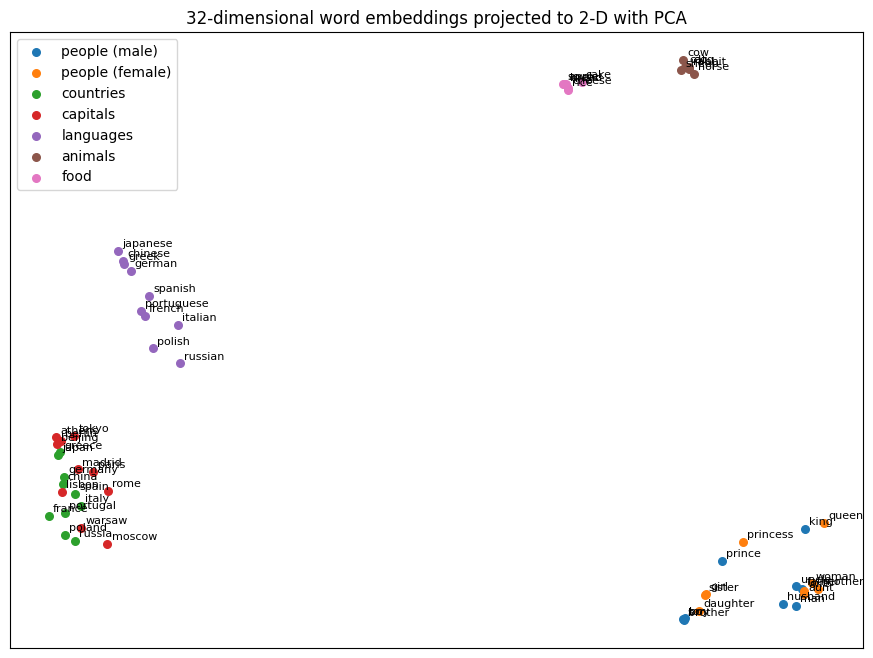

In [6]:
groups = {"people (male)": [p[0] for p in people], "people (female)": [p[1] for p in people],
          "countries": [c[0] for c in countries], "capitals": [c[1] for c in countries], "languages": [c[2] for c in countries],
          "animals": animals, "food": foods}
words = [w for ws in groups.values() for w in ws]
X = emb[[stoi[w] for w in words]].numpy()
X = X - X.mean(0)
U, S, Vt = np.linalg.svd(X, full_matrices=False)       # PCA by hand: project onto the top-2 directions of variance
P = X @ Vt[:2].T
fig, ax = plt.subplots(figsize=(11, 8))
k = 0
for (name, ws), color in zip(groups.items(), plt.cm.tab10.colors):
    pts = P[k:k + len(ws)]; k += len(ws)
    ax.scatter(pts[:, 0], pts[:, 1], color=color, label=name, s=30)
    for (x, y), w in zip(pts, ws):
        ax.annotate(w, (x, y), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.legend(); ax.set_title("32-dimensional word embeddings projected to 2-D with PCA"); ax.set_xticks([]); ax.set_yticks([])
plt.show()

### Analogies: relationships become directions

If *man → woman* and *king → queen* differ in the same way (gender), the difference vectors should be roughly equal, so

$$ \vec{\text{queen}} \approx \vec{\text{king}} - \vec{\text{man}} + \vec{\text{woman}} $$

We answer "*a* is to *b* as *c* is to ?" by computing $\vec b - \vec a + \vec c$ and returning the most similar word that is not one of the three inputs.

In [7]:
def analogy(a, b, c, E=None, among=None):
    # "a is to b as c is to ?"; optionally restrict the answer to a list of candidate words
    E = emb if E is None else E
    q = F.normalize(E[stoi[b]] - E[stoi[a]] + E[stoi[c]], dim=0)
    for i in (E @ q).argsort(descending=True):
        if itos[i] not in (a, b, c) and (among is None or itos[i] in among):
            return itos[i]

for a, b, c in [("man", "woman", "king"), ("king", "queen", "prince"), ("boy", "girl", "brother"),
                ("paris", "france", "rome"), ("france", "french", "japan"), ("berlin", "germany", "madrid")]:
    print(f"{a} : {b}  ::  {c} : {analogy(a, b, c)}")

def score(tests):
    return np.mean([analogy(a, b, c) == d for a, b, c, d in tests])

gender_tests = [(m1, f1, m2, f2) for m1, f1, *_ in people for m2, f2, *_ in people if m1 != m2]
capital_tests = [(ci1, co1, ci2, co2) for co1, ci1, _ in countries for co2, ci2, _ in countries if co1 != co2]
language_tests = [(co1, la1, co2, la2) for co1, _, la1 in countries for co2, _, la2 in countries if co1 != co2]
print()
for name, tests in [("male → female", gender_tests), ("capital → country", capital_tests), ("country → language", language_tests)]:
    print(f"{name:20s} {score(tests):6.1%} of {len(tests)} analogies correct")

man : woman  ::  king : queen
king : queen  ::  prince : princess
boy : girl  ::  brother : sister
paris : france  ::  rome : italy
france : french  ::  japan : japanese
berlin : germany  ::  madrid : spain

male → female         38.9% of 72 analogies correct
capital → country    100.0% of 90 analogies correct
country → language    98.9% of 90 analogies correct


Geography analogies come out almost perfectly, from nothing but co-occurrence statistics. The gender analogies are harder, and the misses are informative: the people in this corpus differ along several axes at once (gender, royalty, age, family role), so the answer to *son : daughter :: brother : ?* has to fight with nearby words that share most of those axes. Real word2vec embeddings make the same kinds of mistakes.

## 5. Embeddings inherit the biases of their text

Our corpus said *the engineer … he* 85% of the time and *the nurse … she* 85% of the time. The model has no idea that this is a social pattern rather than a fact about engineering, so it learns it. Bolukbasi et al. (2016) found the same thing in embeddings trained on news articles ("man is to computer programmer as woman is to homemaker").

We can measure it: build a **gender direction** $g$ by averaging the differences of clearly gendered pairs, then project each occupation onto it. Positive means "closer to *he*", negative means "closer to *she*".

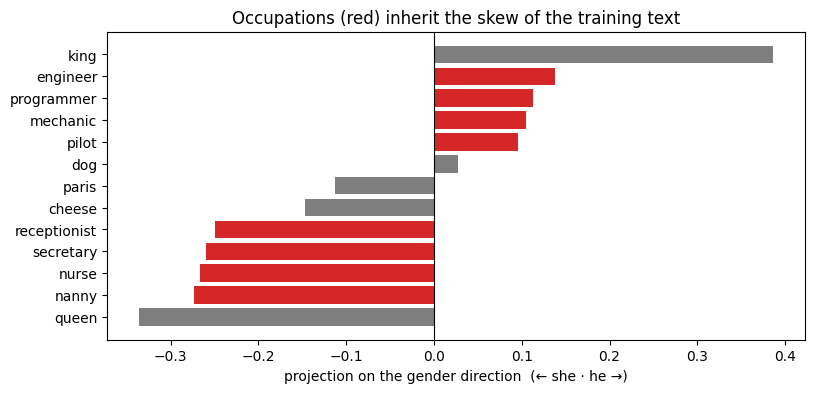

man : engineer :: woman : nanny
he  : pilot    :: she   : nanny

man : <he-job> :: woman : ?   (answer restricted to occupations)
  engineer     → nanny
  pilot        → nanny
  mechanic     → nanny
  programmer   → nanny
100% of answers are 'she' occupations


In [8]:
definitional = [("he", "she"), ("man", "woman"), ("king", "queen"), ("father", "mother"), ("boy", "girl"), ("his", "her")]
g = F.normalize(sum(emb[stoi[m]] - emb[stoi[f]] for m, f in definitional), dim=0)

occupations = jobs_he + jobs_she
proj = {w: (emb[stoi[w]] @ g).item() for w in occupations + ["dog", "cheese", "paris", "king", "queen"]}
fig, ax = plt.subplots(figsize=(9, 4))
order = sorted(proj, key=proj.get)
ax.barh(order, [proj[w] for w in order], color=["#d62728" if w in occupations else "#7f7f7f" for w in order])
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("projection on the gender direction  (← she · he →)")
ax.set_title("Occupations (red) inherit the skew of the training text"); plt.show()

print("man : engineer :: woman :", analogy("man", "engineer", "woman"))
print("he  : pilot    :: she   :", analogy("he", "pilot", "she"))

def bias_probe(E):
    # for each "he" occupation, which occupation does man -> woman map it to?
    flips = [analogy("man", job, "woman", E=E, among=occupations) for job in jobs_he]
    return flips, np.mean([f in jobs_she for f in flips])

flips, rate = bias_probe(emb)
print(f"\nman : <he-job> :: woman : ?   (answer restricted to occupations)")
for job, f in zip(jobs_he, flips):
    print(f"  {job:12s} → {f}")
print(f"{rate:.0%} of answers are 'she' occupations")

### Removing the bias: neutralise

The simplest fix from the same paper is to **neutralise** words that should be gender-neutral: subtract their component along $g$, so they sit exactly halfway between *he* and *she*:

$$ \vec w_{\text{debiased}} = \vec w - (\vec w \cdot g)\, g $$

Words whose gender is part of their meaning (*king*, *mother*) are left alone.

In [9]:
emb_db = emb.clone()
for w in occupations:
    v = emb_db[stoi[w]]
    emb_db[stoi[w]] = F.normalize(v - (v @ g) * g, dim=0)

print(f"{'occupation':14s} {'before':>8s} {'after':>8s}")
for w in occupations:
    print(f"{w:14s} {(emb[stoi[w]] @ g).item():8.3f} {(emb_db[stoi[w]] @ g).item():8.3f}")
flips_db, rate_db = bias_probe(emb_db)
print("\nafter neutralising, man : <he-job> :: woman : ?")
for job, f in zip(jobs_he, flips_db):
    print(f"  {job:12s} → {f}")
print(f"{rate_db:.0%} of answers are 'she' occupations (before: {rate:.0%})")
print("\nnearest words to 'nurse' after neutralising:", [w for w, _ in nearest("nurse", 4, E=emb_db)])

occupation       before    after
engineer          0.138   -0.000
pilot             0.095   -0.000
mechanic          0.104    0.000
programmer        0.113   -0.000
nurse            -0.266   -0.000
receptionist     -0.250   -0.000
nanny            -0.273    0.000
secretary        -0.259   -0.000

after neutralising, man : <he-job> :: woman : ?
  engineer     → pilot
  pilot        → engineer
  mechanic     → pilot
  programmer   → engineer
0% of answers are 'she' occupations (before: 100%)

nearest words to 'nurse' after neutralising: ['secretary', 'engineer', 'receptionist', 'programmer']


The projections are now exactly zero and, on this toy corpus, the analogy probe no longer maps "male" jobs to "female" ones. The nearest neighbours of *nurse* are mixed now, but its old group still ranks first: some of the bias survives in other directions. Two caveats matter in practice:

* On real embeddings, later research (Gonen & Goldberg, 2019) showed that this kind of projection mostly **hides** bias rather than removing it. Gender is learned along many directions at once, so removing one of them leaves the occupation words clustered by their old gender, and a classifier can usually still recover it. Bias in a model is ultimately a property of its training data.
* Modern language models (notebook 08) still start with an embedding layer exactly like this one, and they inherit the patterns of their training text in the same way, which is why evaluating them for bias remains an active field.

---
# Part B · Sequence-to-sequence translation with attention

## 6. The problem

Translation maps a sequence to another sequence of **different length and order**:

> *the red car* → *el coche rojo* (adjective moves after the noun)
> *he does not eat* → *él no come* (English needs "does", Spanish does not)

The **encoder-decoder** architecture (Sutskever et al., 2014) handles this:
1. An **encoder** RNN reads the source sentence into hidden states.
2. A **decoder** RNN generates the target one word at a time, each step conditioned on the previous word.

The original version squeezed the whole sentence into **one** vector, a bottleneck for long sentences. **Attention** (Bahdanau et al., 2014) lets the decoder look back at *all* encoder states at every step and choose which ones matter. That idea, taken to its extreme, is the transformer (notebook 07).

```
              encoder (bidirectional GRU)                     decoder (GRU + attention)
 the → red → car → <eos>                     <sos> → el → coche → rojo
   h1    h2    h3    h4  ─────── attention ─────►  each step: weights α over h1..h4,
                                                   context = Σ α_i h_i, predict next word
```

## 7. A synthetic English → Spanish corpus

To train in minutes on a CPU we generate sentences from a small grammar: subject + (negation) + verb + article + noun + (adjective). It still contains the hard parts: verb conjugation, gender agreement (*rojo/roja*, *el/la*), adjective reordering and the vanishing English auxiliary "do/does".

In [10]:
subjects = [("i", "yo", 0), ("you", "tú", 1), ("he", "él", 2), ("she", "ella", 2), ("we", "nosotros", 3), ("they", "ellos", 4)]
verbs = {  # english base, english 3rd person, spanish conjugations for yo/tú/él/nosotros/ellos
    "eat":  ("eats",  ["como", "comes", "come", "comemos", "comen"]),
    "see":  ("sees",  ["veo", "ves", "ve", "vemos", "ven"]),
    "want": ("wants", ["quiero", "quieres", "quiere", "queremos", "quieren"]),
    "buy":  ("buys",  ["compro", "compras", "compra", "compramos", "compran"]),
    "have": ("has",   ["tengo", "tienes", "tiene", "tenemos", "tienen"]),
    "need": ("needs", ["necesito", "necesitas", "necesita", "necesitamos", "necesitan"]),
}
nouns = [("apple", "manzana", "f"), ("book", "libro", "m"), ("car", "coche", "m"), ("house", "casa", "f"), ("dog", "perro", "m"),
         ("table", "mesa", "f"), ("bread", "pan", "m"), ("letter", "carta", "f"), ("cat", "gato", "m"), ("shirt", "camisa", "f")]
adjectives = [("red", "rojo", "roja"), ("big", "grande", "grande"), ("new", "nuevo", "nueva"),
              ("small", "pequeño", "pequeña"), ("old", "viejo", "vieja"), ("white", "blanco", "blanca"), (None, None, None)]
articles = {"the": {"m": "el", "f": "la"}, "a": {"m": "un", "f": "una"}}

pairs = []
for en_s, es_s, person in subjects:
    third = en_s in ("he", "she")
    for v, (v3, conj) in verbs.items():
        for neg in (False, True):
            for art in articles:
                for en_n, es_n, g in nouns:
                    for en_a, es_am, es_af in adjectives:
                        if neg:
                            en_v = ("does not " if third else "do not ") + v
                            es_v = "no " + conj[person]
                        else:
                            en_v = v3 if third else v
                            es_v = conj[person]
                        first = en_a or en_n
                        en_art = "an" if art == "a" and first[0] in "aeiou" else art
                        en_np = f"{en_art} {en_a + ' ' if en_a else ''}{en_n}"
                        es_np = f"{articles[art][g]} {es_n}" + (f" {es_am if g == 'm' else es_af}" if en_a else "")
                        pairs.append((f"{en_s} {en_v} {en_np}", f"{es_s} {es_v} {es_np}"))

random.seed(0); random.shuffle(pairs)
print(len(pairs), "sentence pairs, e.g.:")
for p in pairs[:6]:
    print("  EN:", p[0], "\n  ES:", p[1])

10080 sentence pairs, e.g.:
  EN: you do not eat a small table 
  ES: tú no comes una mesa pequeña
  EN: you do not want an apple 
  ES: tú no quieres una manzana
  EN: she eats an old apple 
  ES: ella come una manzana vieja
  EN: she needs a red cat 
  ES: ella necesita un gato rojo
  EN: he needs a white dog 
  ES: él necesita un perro blanco
  EN: i do not buy a bread 
  ES: yo no compro un pan


In [11]:
class Vocab:
    def __init__(self, sentences):
        self.itos = ["<pad>", "<sos>", "<eos>"] + sorted({w for s in sentences for w in s.split()})
        self.stoi = {w: i for i, w in enumerate(self.itos)}
    def encode(self, s):
        return [self.stoi[w] for w in s.split()] + [2]
    def decode(self, ids):
        return " ".join(self.itos[i] for i in ids if i > 2)

src_vocab, tgt_vocab = Vocab([p[0] for p in pairs]), Vocab([p[1] for p in pairs])
PAD, SOS, EOS = 0, 1, 2

def batchify(pp):
    src = [torch.tensor(src_vocab.encode(a)) for a, _ in pp]
    tgt = [torch.tensor(tgt_vocab.encode(b)) for _, b in pp]
    return (nn.utils.rnn.pad_sequence(src, batch_first=True, padding_value=PAD),
            nn.utils.rnn.pad_sequence(tgt, batch_first=True, padding_value=PAD))

n_test = 1000
train_pairs, test_pairs = pairs[n_test:], pairs[:n_test]
print(f"source vocab {len(src_vocab.itos)} words, target vocab {len(tgt_vocab.itos)} words")
print(f"train {len(train_pairs)} pairs, test {len(test_pairs)} pairs (sentences the model never sees)")

source vocab 43 words, target vocab 65 words
train 9080 pairs, test 1000 pairs (sentences the model never sees)


## 8. The model: bidirectional GRU encoder + attention decoder

At decoder step $t$ with hidden state $s_{t-1}$, **additive (Bahdanau) attention** scores every encoder state $h_i$, normalises with softmax, and builds a context vector:

$$ e_{t,i} = v^\top \tanh(W_s s_{t-1} + W_h h_i), \qquad \alpha_{t,i} = \text{softmax}_i(e_{t,i}), \qquad c_t = \sum_i \alpha_{t,i} h_i $$

The decoder then consumes $[\text{embedding}(y_{t-1}); c_t]$. Both encoder and decoder start with an `nn.Embedding` layer: the same lookup table as in Part A, but here the vectors are learned as a by-product of translating rather than from a separate objective. During training we use **teacher forcing**: the decoder input at each step is the *true* previous word, not its own guess.

In [12]:
class Encoder(nn.Module):
    def __init__(self, vocab, emb=64, hid=128):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb, padding_idx=PAD)
        self.rnn = nn.GRU(emb, hid, batch_first=True, bidirectional=True)
        self.bridge = nn.Linear(2 * hid, hid)
    def forward(self, src):
        out, h = self.rnn(self.emb(src))                             # out: (B, S, 2H)
        h0 = torch.tanh(self.bridge(torch.cat([h[0], h[1]], dim=-1)))  # initial decoder state
        return out, h0

class AdditiveAttention(nn.Module):
    def __init__(self, hid):
        super().__init__()
        self.Ws, self.Wh, self.v = nn.Linear(hid, hid), nn.Linear(2 * hid, hid), nn.Linear(hid, 1, bias=False)
    def forward(self, s, enc_out, mask):
        scores = self.v(torch.tanh(self.Ws(s).unsqueeze(1) + self.Wh(enc_out))).squeeze(-1)   # (B, S)
        scores = scores.masked_fill(~mask, -1e9)                                              # ignore padding
        alpha = scores.softmax(-1)
        return (alpha.unsqueeze(-1) * enc_out).sum(1), alpha

class Decoder(nn.Module):
    def __init__(self, vocab, emb=64, hid=128):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb, padding_idx=PAD)
        self.att = AdditiveAttention(hid)
        self.rnn = nn.GRUCell(emb + 2 * hid, hid)
        self.out = nn.Linear(hid + 2 * hid + emb, vocab)
    def step(self, y_prev, s, enc_out, mask):
        e = self.emb(y_prev)
        ctx, alpha = self.att(s, enc_out, mask)
        s = self.rnn(torch.cat([e, ctx], -1), s)
        return self.out(torch.cat([s, ctx, e], -1)), s, alpha

class Seq2Seq(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc, self.dec = Encoder(len(src_vocab.itos)), Decoder(len(tgt_vocab.itos))
    def forward(self, src, tgt):                       # teacher forcing
        enc_out, s = self.enc(src)
        mask = src != PAD
        y_prev = torch.full((src.shape[0],), SOS)
        logits = []
        for t in range(tgt.shape[1]):
            lg, s, _ = self.dec.step(y_prev, s, enc_out, mask)
            logits.append(lg); y_prev = tgt[:, t]
        return torch.stack(logits, 1)
    @torch.no_grad()
    def translate(self, sentence, max_len=12):
        src = torch.tensor([src_vocab.encode(sentence)])
        enc_out, s = self.enc(src)
        y, out, alphas = torch.tensor([SOS]), [], []
        for _ in range(max_len):
            lg, s, a = self.dec.step(y, s, enc_out, src != PAD)
            y = lg.argmax(-1)                          # greedy decoding
            if y.item() == EOS: break
            out.append(y.item()); alphas.append(a[0])
        return tgt_vocab.decode(out), torch.stack(alphas) if alphas else None

torch.manual_seed(0)
s2s = Seq2Seq()
print(f"seq2seq parameters: {count_params(s2s):,}")
print("untrained output:", s2s.translate("she does not want the red car")[0])

seq2seq parameters: 440,321
untrained output: necesitas no blanco pequeña camisa blanco pequeña camisa blanco pequeña camisa blanco


In [13]:
opt = torch.optim.Adam(s2s.parameters(), lr=2e-3)
t0, losses = time.time(), []
import copy
checkpoints, step = {}, 0
for epoch in range(6):
    random.shuffle(train_pairs)
    for i in range(0, len(train_pairs), 64):
        src, tgt = batchify(train_pairs[i:i + 64])
        logits = s2s(src, tgt)
        loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), tgt.reshape(-1), ignore_index=PAD)
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(s2s.parameters(), 1.0); opt.step()
        losses.append(loss.item())
        step += 1
        if step in (40, 80):
            checkpoints[step] = copy.deepcopy(s2s.state_dict())   # kept for the beam-search comparison in section 10
    print(f"epoch {epoch + 1}: loss {np.mean(losses[-100:]):.4f}  ({time.time() - t0:.0f}s)")

epoch 1: loss 0.0354  (16s)


epoch 2: loss 0.0016  (32s)


epoch 3: loss 0.0008  (48s)


epoch 4: loss 0.0004  (65s)


epoch 5: loss 0.0003  (82s)


epoch 6: loss 0.0002  (98s)


In [14]:
s2s.eval()
exact = sum(s2s.translate(a)[0] == b for a, b in test_pairs)
print(f"exact-match accuracy on {len(test_pairs)} unseen sentences: {exact / len(test_pairs):.1%}\n")
for a, b in test_pairs[:6]:
    hyp = s2s.translate(a)[0]
    print(f"EN : {a}\nES*: {b}\nOUT: {hyp}  {'✓' if hyp == b else '✗'}\n")

exact-match accuracy on 1000 unseen sentences: 99.9%

EN : you do not eat a small table
ES*: tú no comes una mesa pequeña
OUT: tú no comes una mesa pequeña  ✓

EN : you do not want an apple
ES*: tú no quieres una manzana
OUT: tú no quieres una manzana  ✓

EN : she eats an old apple
ES*: ella come una manzana vieja
OUT: ella come una manzana vieja  ✓

EN : she needs a red cat
ES*: ella necesita un gato rojo
OUT: ella necesita un gato rojo  ✓

EN : he needs a white dog
ES*: él necesita un perro blanco
OUT: él necesita un perro blanco  ✓

EN : i do not buy a bread
ES*: yo no compro un pan
OUT: yo no compro un pan  ✓



## 9. Visualising attention

Each row shows which English words the decoder looked at while producing that Spanish word. Look for:
* the **crossing** pattern where the adjective is reordered (*red car* → *coche rojo*),
* "no" attending to "not", and the conjugated verb attending to the English verb,
* the subject pronoun sometimes attending to the word *next to* the English subject (for example *ella* → *does*). The encoder is bidirectional, so every $h_i$ already mixes in its neighbours (*does* only appears after *he/she*). Attention weights are a useful hint about what the model uses, not an exact word alignment.

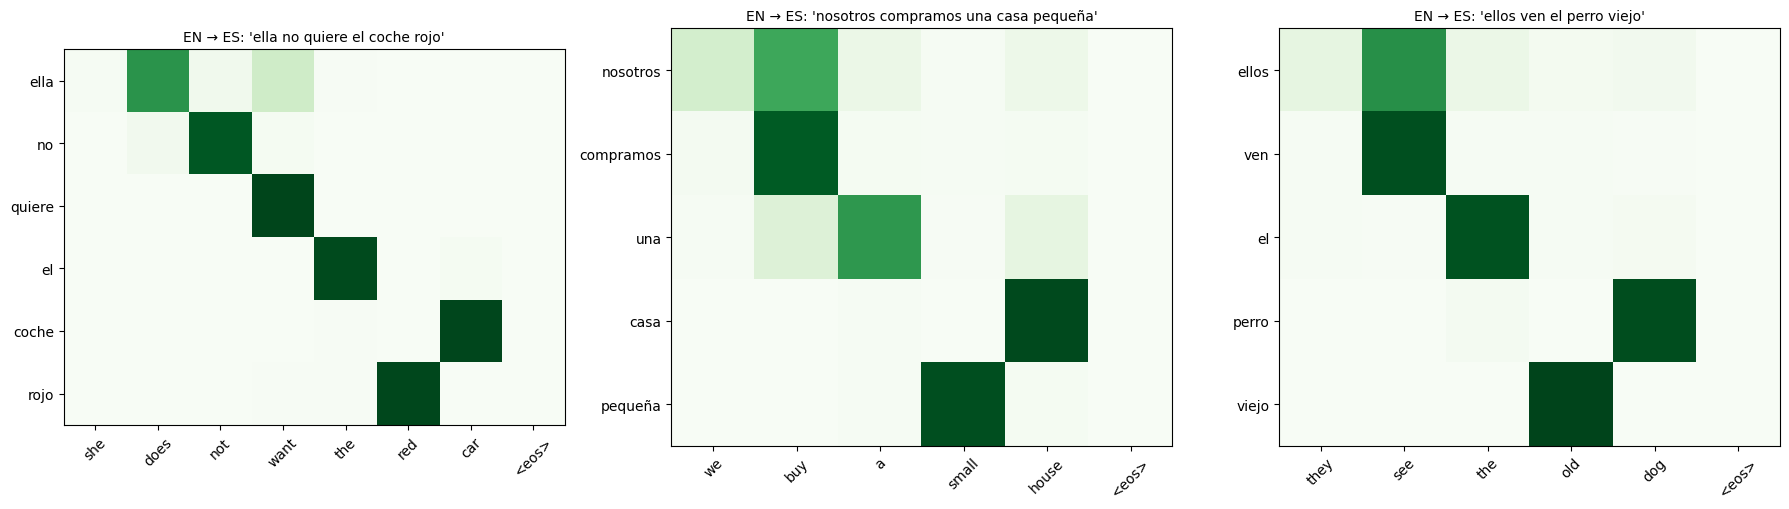

In [15]:
examples = ["she does not want the red car", "we buy a small house", "they see the old dog"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, sent in zip(axes, examples):
    out, alpha = s2s.translate(sent)
    ax.imshow(alpha.numpy(), cmap="Greens", vmin=0, vmax=1)
    ax.set_xticks(range(len(sent.split()) + 1)); ax.set_xticklabels(sent.split() + ["<eos>"], rotation=45)
    ax.set_yticks(range(len(out.split()))); ax.set_yticklabels(out.split())
    ax.set_title(f"EN → ES: '{out}'", fontsize=10)
plt.tight_layout(); plt.show()

## 10. Beam search: searching for a better sentence

`translate` uses **greedy decoding**: at each step it commits to the single most likely word. That is not the same as finding the most likely *sentence*: a word that looks best now can force a bad continuation later.

**Beam search** keeps the $B$ most probable partial translations at every step. Each one is extended by every possible next word, and only the best $B$ of all those candidates survive. Scores are summed log-probabilities, divided by length so that longer outputs are not unfairly penalised. With $B = 1$ it reduces to greedy decoding.

The effect is easiest to see on a model that is still uncertain, so we compare both decoders on checkpoints saved early in the first epoch, as well as on the final model.

In [16]:
@torch.no_grad()
def beam_translate(model, sentence, beam=4, max_len=12):
    src = torch.tensor([src_vocab.encode(sentence)])
    enc_out, s0 = model.enc(src)
    mask = src != PAD
    beams = [(0.0, [SOS], s0)]                   # (sum of log-probs, tokens, decoder state)
    finished = []
    for _ in range(max_len):
        candidates = []
        for score, toks, s in beams:
            lg, s_new, _ = model.dec.step(torch.tensor([toks[-1]]), s, enc_out, mask)
            logp = lg.log_softmax(-1)[0]
            top = logp.topk(beam)
            for lp, idx in zip(top.values.tolist(), top.indices.tolist()):
                candidates.append((score + lp, toks + [idx], s_new))
        candidates.sort(key=lambda c: c[0] / (len(c[1]) - 1), reverse=True)
        beams = []
        for c in candidates:
            (finished if c[1][-1] == EOS else beams).append(c)
            if len(beams) == beam:
                break
        if not beams or len(finished) >= beam:
            break
    best = max(finished + beams, key=lambda c: c[0] / (len(c[1]) - 1))
    return tgt_vocab.decode(best[1][1:])

snapshots = {}
for k, state in checkpoints.items():
    snapshots[f"after {k} batches"] = Seq2Seq(); snapshots[f"after {k} batches"].load_state_dict(state); snapshots[f"after {k} batches"].eval()
snapshots["fully trained"] = s2s
early = snapshots["after 40 batches"]
print(f"{'model':22s} {'greedy':>8s} {'beam=4':>8s}   (exact match on {len(test_pairs)} unseen sentences)")
for name, m in snapshots.items():
    g = np.mean([m.translate(a)[0] == b for a, b in test_pairs])
    bs = np.mean([beam_translate(m, a) == b for a, b in test_pairs])
    print(f"{name:22s} {g:8.1%} {bs:8.1%}")

fixed, broken = [], []
for a, b in test_pairs:
    gr, bm = early.translate(a)[0], beam_translate(early, a)
    if gr != b and bm == b: fixed.append((a, gr, bm))
    if gr == b and bm != b: broken.append((a, gr, bm))
print(f"\nafter 40 batches: beam search fixes {len(fixed)} sentences and breaks {len(broken)}")
for title, rows in [("fixed by beam search", fixed[:2]), ("broken by beam search", broken[:2])]:
    for a, gr, bm in rows:
        print(f"\n[{title}]\nEN    : {a}\ngreedy: {gr}\nbeam  : {bm}")

model                    greedy   beam=4   (exact match on 1000 unseen sentences)


after 40 batches          55.8%    54.2%


after 80 batches          94.8%    94.4%


fully trained             99.9%   100.0%



after 40 batches: beam search fixes 25 sentences and breaks 41

[fixed by beam search]
EN    : she eats an old apple
greedy: ella no come una manzana vieja
beam  : ella come una manzana vieja

[fixed by beam search]
EN    : she has a big letter
greedy: ella come una carta grande
beam  : ella tiene una carta grande

[broken by beam search]
EN    : she wants the big cat
greedy: ella quiere el gato grande
beam  : ella come el gato grande

[broken by beam search]
EN    : i have the small dog
greedy: yo tengo el perro pequeño
beam  : yo veo el perro pequeño


The result is instructive: on the undertrained model, beam search fixes some sentences but breaks even more, so overall accuracy goes slightly *down*. Beam search can only find translations the model already scores highly. It helps when the error is an *early commitment* (the right sentence had a higher total score than the greedy one), and it cannot help, or even hurts, when the model's probabilities are themselves wrong, as they are early in training. In real translation systems, where models are good but not certain, beam search usually gives a modest, consistent gain, at the cost of $B$ times more computation per sentence. Beam search is standard in translation and speech recognition; chat models usually *sample* instead (notebook 08), because for open-ended text the single most likely sentence tends to be dull and repetitive.

## Summary

| Idea | What it does | Where it lives on |
|---|---|---|
| word embeddings | words become vectors; similar usage → nearby vectors; relations → directions | the first layer of every language model |
| bias in embeddings | statistical patterns in the text become geometry, including unwanted ones | bias evaluation of modern LLMs |
| encoder-decoder | read a whole input, then generate an output of a different length | translation, summarisation, speech recognition |
| attention | at each output step, look back at every input position and choose what matters | **the transformer** (notebook 07) |
| beam search | search for a likely *sentence*, not a sequence of likely words | translation and speech decoders |

The attention weights you plotted in section 9 are the seed of the transformer. Notebook 07 drops the recurrence entirely and builds a network **only** from attention and feed-forward MLPs.

## Exercises

1. **Embeddings:** change the embedding size to 8 and to 128. How do the analogy scores change? What about the window size (1 vs 5)?
2. **Embeddings:** use only the centre vectors, without centring (`emb = F.normalize(sg.centre.weight.detach(), dim=1)`). Which analogy family breaks, and why might a shared direction hurt it most?
3. **Embeddings:** remove the skew (use 0.5 for every occupation in `sentence`) and retrain. What happens to the bias plot?
4. **Embeddings:** after neutralising, print `nearest("nurse", E=emb_db)`. Which words are still closest, and what does that say about the method?
5. **Seq2seq:** remove attention (use only the final encoder state as context). How much does accuracy drop, and does beam search recover any of it?
6. **Seq2seq:** hold out every sentence containing *"white cat"* from training. Can the model translate *"the white cat"* correctly (compositional generalisation)?